> **Wurzburg-Fassung** von `../03_wetter.ipynb`, automatisch erzeugt am 05.10.2026 05:37 UTC mit `stadt_fassungen.py` (Parameter `STADT = "wurzburg"`, Bilder in `04_images/wurzburg/`). Code und Texte nur im Hauptnotebook ändern und neu erzeugen. Die Texte gelten für jeden Standort; die Zahlen dieser Stadt stehen in den Ausgaben, Kontrollwerte je Stadt in den Tabellen.

# 03 – Bee Haven: Wetterdaten und Sonnenstand (N3)

**Ziel:** Außenwetter und Sonnenstand für den Standort (Parameter `STADT`, Koordinaten aus `konfiguration/standorte.csv`) bereitstellen, damit Gold (N4) und die Analyse (N5) das Flugverhalten mit Außentemperatur, Regen, Sonnenschein und Tageszeit (Tag · Dämmerung · Nacht) vergleichen kann.

**Quellen:**
- Wetter: **Bright Sky** (`api.brightsky.dev`) – freie Schnittstelle zu den Open-Data-Messwerten des **Deutschen Wetterdienstes (DWD)**, stündlich, ohne Anmeldung; Vorbild: Kurs-Notebooks 02–04.
- Sonnenstand: Berechnung nach den Formeln der US-Wetter- und Ozeanbehörde **NOAA** („General Solar Position Calculations“), gegengeprüft mit **Open-Meteo**.

**Grundsatz:** Rohantwort unverändert nach `bronze/archive` (Archiv), aufbereitete Daten mit UTC-Zeitstempel nach `silver/cleaned` – wie bei den Sensordaten.

**Quellenangaben und Lizenzen:** Datenbasis: Deutscher Wetterdienst (DWD Open Data, über Bright Sky – https://brightsky.dev/docs/) · Sonnenstand: NOAA, „General Solar Position Calculations“ (https://gml.noaa.gov/grad/solcalc/solareqns.PDF) · Gegenprüfung: Open-Meteo Historical Weather API (https://open-meteo.com/en/docs/historical-weather-api), Lizenz CC BY 4.0.

**Ergebnistexte:** gelten für jeden Standort; die Zahlen stehen in der Ausgabe. „Kontrollwerte“ = erwartete Werte je Stadt (Stand 02.10.2026).

## 0. Bibliotheken, Pfade und Standort

**Kontrollwert:** keine Ausgabe, keine Fehlermeldung

In [1]:
# --- Parameter: Standort (neue Stadt = Zeile in lakehouse/konfiguration/standorte.csv + Ordner in silver/processing) ---
STADT = "wurzburg"                                       # Standort = Unterordner in bronze/silver/gold und Teil der Dateinamen

# --- Bibliotheken laden ---
import time                                   # kurze Pause zwischen Wiederholungsversuchen
from pathlib import Path                      # Ordner- und Dateipfade
from datetime import datetime, timezone       # UTC-Zeitstempel für Dateinamen
import numpy as np                            # Winkelfunktionen für den Sonnenstand
import pandas as pd                           # Tabellen
import requests                               # Abruf der Wetter-Schnittstelle (HTTP)
import matplotlib.pyplot as plt               # Diagramme
import matplotlib.dates as mdates             # Datumsformat der x-Achse

# --- Pfade (gleiche Struktur wie in Azure) ---
PROJEKT = Path.cwd().parent                                              # Projektordner = eine Ebene über 03_notebooks_ITS-Data
LAKE = PROJEKT / "02_daten_ITS-Data" / "lakehouse"                       # lokaler Spiegel des Azure-Containers
ZWISCHENSTAND = PROJEKT / "02_daten_ITS-Data" / "zwischenstand"          # Ergebnis aus N1 (für den Zeitraum)
BRONZE_WETTER = LAKE / "bronze" / "archive" / STADT / "wetter"         # Rohantwort (Archiv, nie überschreiben)
CLEANED = LAKE / "silver" / "cleaned" / STADT                          # aufbereitete Daten
BILDER = PROJEKT / "04_images" / STADT                                   # Grafiken je Stadt (04_images/<stadt>/)

# --- Standortdaten aus der Konfiguration (Koordinaten, Zeitzone) ---
standorte = pd.read_csv(PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "konfiguration" / "standorte.csv", index_col="stadt")
if STADT not in standorte.index:                          # unbekannte Stadt -> sofort abbrechen statt mit falschen Daten weiterrechnen
    raise ValueError(f"Standort '{STADT}' fehlt in konfiguration/standorte.csv – Zeile mit Koordinaten und Zeitzone ergänzen")
ORT = standorte.loc[STADT]                                # eine Zeile: name, breite, laenge, zeitzone, quelle

# --- Sensor-Regeln je Standort (Einheit der Rohdaten, gültiger Bereich) und bekannte Ausfallzeiträume ---
KONFIG = PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "konfiguration"                  # Ordner mit den Konfigurationstabellen
sensoren_cfg = pd.read_csv(KONFIG / "sensoren.csv")                                    # eine Zeile je Stadt und Sensor
REGELN = sensoren_cfg[sensoren_cfg["stadt"] == STADT].set_index("sensor")              # Regeln dieser Stadt: einheit_roh, min, max
ausschluesse = pd.read_csv(KONFIG / "ausschluesse.csv")                                # bekannte Ausfallzeiträume (z. B. Stock nicht auf Waage)
AUSSCHLUESSE = ausschluesse[ausschluesse["stadt"] == STADT].copy()                     # nur Zeiträume dieser Stadt
AUSSCHLUESSE[["von_utc", "bis_utc"]] = AUSSCHLUESSE[["von_utc", "bis_utc"]].apply(pd.to_datetime, utc=True)  # Text -> UTC-Zeit
ZEITZONE = ORT["zeitzone"]                                # Ortszeit der Rohdaten (Deutschland: Europe/Berlin)
BREITE, LAENGE = float(ORT["breite"]), float(ORT["laenge"])   # Breitengrad (Nord), Längengrad (Ost) des Bienenstocks

**Ergebnis:**

Bibliotheken, Pfade und Standort ohne Fehler geladen. Die Koordinaten stammen aus der Standort-Tabelle – eine fehlende Stadt führt zu einer klaren Fehlermeldung statt zu falschem Wetter.

## 1. Zeitraum der Sensordaten bestimmen

**Warum?** Wetter wird genau für den Zeitraum gebraucht, in dem der Bienenstock gemessen hat – nicht mehr (Datenmenge, Kosten) und nicht weniger.

**Kontrollwert:** Zeitraum aus N1 (erste und letzte Messung, UTC)

In [2]:
# --- Frühesten und spätesten Zeitpunkt über alle 4 Sensoren suchen ---
zeiten = [pd.read_parquet(ZWISCHENSTAND / f"{s}_{STADT}_n1.parquet", columns=["zeit_utc"])["zeit_utc"]  # nur die Zeitspalte laden
          for s in ["flow", "humidity", "temperature", "weight"]]
start = min(z.min() for z in zeiten)                   # frühester Messzeitpunkt
ende = max(z.max() for z in zeiten)                    # spätester Messzeitpunkt
print("Zeitraum (UTC):", start, "bis", ende)

Zeitraum (UTC): 2017-01-01 04:00:00+00:00 bis 2019-05-20 11:48:00+00:00


**Ergebnis:** Erste und letzte Messung in UTC (Ausgabe); das Wetter wird für ganze Tage dieses Zeitraums abgerufen.

| Kontrollwerte | Zeitraum der Sensordaten (UTC) |
| :-- | :-- |
| Schwartau | 01.01.2017 12:00 bis 31.05.2019 12:15 |
| Würzburg | 01.01.2017 04:00 bis 20.05.2019 11:48 |

## 2. Wetter abrufen und als Rohdaten archivieren (Bronze)

**Wie?** Eine Anfrage an Bright Sky mit Koordinaten und Zeitraum; Einheiten `dwd` (°C, mm, Minuten, km/h). Bei Fehlern bis zu 3 Versuche (wie im Kurs-Notebook).

**Warum archivieren?** Die Rohantwort bleibt unverändert erhalten – wenn die Aufbereitung falsch war, kann sie ohne neuen Abruf wiederholt werden.

**Eigene Erwartung (Rechnung):** Anzahl Tage × 24 Stunden Stundenwerte, dazu eine Liste der Wetterstationen

In [3]:
# --- Wetterdaten von Bright Sky (DWD) abrufen ---
def wetter_abrufen(breite, laenge, von, bis, versuche=4):
    """Stündliches Wetter als JSON holen; bei Fehlern mehrfach versuchen."""
    parameter = {"lat": breite, "lon": laenge,           # Standort
                 "date": von, "last_date": bis,          # Zeitraum (ganze Tage)
                 "tz": "UTC", "units": "dwd",            # Zeiten in UTC, Einheiten des DWD
                 "max_dist": 50_000}                     # Stationen im Umkreis von 50 km
    fehler = None
    for versuch in range(1, versuche + 1):               # mehrere Versuche (kurze Störungen überbrücken)
        try:
            antwort = requests.get("https://api.brightsky.dev/weather", params=parameter, timeout=120)
            if antwort.status_code == 200:               # 200 = erfolgreich
                return antwort.json()                    # leere/kaputte Antwort -> Fehler -> nächster Versuch
            fehler = f"Status {antwort.status_code}"
        except (requests.RequestException, ValueError) as e:   # Netzwerkfehler oder ungültiges JSON
            fehler = repr(e)
        time.sleep(5 * versuch)                          # 5, 10, 15 … Sekunden warten, dann erneut versuchen
    raise RuntimeError(f"Bright Sky nach {versuche} Versuchen nicht erreichbar ({fehler})")

roh = wetter_abrufen(BREITE, LAENGE, start.strftime("%Y-%m-%d"), (ende + pd.Timedelta(days=1)).strftime("%Y-%m-%d"))
wetter_roh = pd.json_normalize(roh["weather"])           # Liste der Stundenwerte → Tabelle
stationen = pd.json_normalize(roh["sources"])            # Liste der Wetterstationen → Tabelle

# --- Rohdaten unverändert archivieren (Parquet, mit UTC-Zeitstempel) ---
stempel = datetime.now(timezone.utc).strftime("%Y-%m-%d_%H%M%S")        # Zeitpunkt des Abrufs
BRONZE_WETTER.mkdir(parents=True, exist_ok=True)                         # Ordner anlegen, falls nötig
wetter_roh.to_parquet(BRONZE_WETTER / f"wetter_roh__{stempel}_UTC.parquet", index=False)
stationen.to_parquet(BRONZE_WETTER / f"stationen_roh__{stempel}_UTC.parquet", index=False)
print(f"{len(wetter_roh):,} Stundenwerte · {wetter_roh.shape[1]} Spalten · {len(stationen)} Stationen")

20,881 Stundenwerte · 27 Spalten · 6 Stationen


**Ergebnis:** Stundenwerte, Spalten und Stationen in der Ausgabe; Rohantwort in `bronze/archive/<stadt>/wetter/` archiviert (Parquet mit UTC-Zeitstempel).

| Kontrollwerte | Stundenwerte · Spalten · Stationen |
| :-- | :-- |
| Schwartau | 21.145 · 32 · 6 |
| Würzburg | 20.881 · 27 · 7 |

## 3. Welche Station liefert welchen Messwert?

**Warum?** Bright Sky nimmt die nächstgelegene Station und ergänzt fehlende Messgrößen automatisch aus Ersatzstationen (`fallback`). Für die Deutung ist wichtig, **wo** z. B. die Außentemperatur gemessen wurde.

**Erwartung laut Schnittstellenbeschreibung:** Bright Sky wählt die nächstgelegene DWD-Station und ergänzt fehlende Messgrößen aus Ersatzstationen (Felder `fallback_source_ids`, OpenAPI-Beschreibung https://api.brightsky.dev/openapi.json) – also Hauptstation in der Nähe, einzelne Messgrößen von Nachbarstationen.

In [4]:
# --- Stationen mit Entfernung ---
print(stationen[["id", "station_name", "distance"]].assign(km=lambda t: (t["distance"] / 1000).round(1)).drop(columns="distance").to_string(index=False))

# --- Je Messgröße: Anteil der Stunden je Station ---
name = stationen.drop_duplicates("id").set_index("id")["station_name"]  # Station-ID → Name
herkunft = {}
for g in ["temperature", "precipitation", "sunshine", "wind_speed", "relative_humidity", "cloud_cover",
          "pressure_msl", "dew_point", "wind_gust_speed", "solar", "condition"]:
    spalte = f"fallback_source_ids.{g}"                                   # Ersatzstation für diese Messgröße (falls vorhanden)
    station = wetter_roh[spalte].fillna(wetter_roh["source_id"]) if spalte in wetter_roh else wetter_roh["source_id"]
    herkunft[g] = station.map(name).value_counts(normalize=True).mul(100).round(1)  # Anteil in %
pd.DataFrame(herkunft).fillna(0)                                          # Tabelle: Station × Messgröße (in %)

    id              station_name   km
  7315                  Würzburg  1.5
239475 Prosselsheim-Seligenstadt 12.3
  7054                 Kitzingen 15.3
115203       Schonungen-Mainberg 38.9
  7153             Niederstetten 43.1
  7397        Neuhütten/Spessart 47.2


,temperature,precipitation,sunshine,wind_speed,relative_humidity,cloud_cover,pressure_msl,dew_point,wind_gust_speed,solar,condition
Kitzingen,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.6
Neuhütten/Spessart,0.0,0.0,0.4,0.2,0.0,0.2,0.0,0.0,0.2,0.0,0.3
Niederstetten,0.0,0.0,0.0,0.0,0.0,0.7,0.0,0.0,0.0,0.0,0.0
Prosselsheim-Seligenstadt,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1
Schonungen-Mainberg,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5
Würzburg,100.0,100.0,99.6,99.8,100.0,99.1,100.0,100.0,99.8,100.0,96.5


**Ergebnis (Befund W1):** Die Ausgabe zeigt je Station die Entfernung und je Messgröße den Anteil der Stunden, den eine Station liefert. Bright Sky nimmt die nächste Station und ergänzt fehlende Messgrößen aus Nachbarstationen – „Außentemperatur“ heißt also: gemessen an der Station mit dem größten Anteil.

| Kontrollwerte | Hauptquelle |
| :-- | :-- |
| Schwartau | Niederschlag aus Bad Schwartau-Groß Parin (2,1 km, 98,6 %); Temperatur, Wind, Feuchte, Bewölkung, Luftdruck, Taupunkt, Böen, Strahlung zu ca. 99 % aus Lübeck-Blankensee (13 km); Sonnenschein 75 % Lübeck-Blankensee / 25 % Bad Schwartau |
| Würzburg | Station Würzburg (1,5 km) für fast alle Messgrößen; einzelne Werte aus Nachbarstationen (bis 47 km, Anteile siehe Ausgabe) |

→ Für Tagesverläufe ausreichend; kleinräumige Unterschiede (z. B. Sonne direkt am Stock) sind nicht erfasst. Liegt die Hauptquelle einer Messgröße weit entfernt (z. B. > 20 km), ist das ein Hinweis für die Analyse (Idee I54, Folgeprojekt Dashboard).

## 4. Datenqualität prüfen

**Prüfungen:** Zeitabstände (erwartet genau 1 Stunde), fehlende Werte je Messgröße, Verteilung der fehlenden Sonnenscheinwerte über die Uhrzeit.

**Eigene Erwartung:** lückenlose Stunden; einzelne fehlende Werte

In [5]:
# --- Zeitabstände ---
wetter_roh["zeit_utc"] = pd.to_datetime(wetter_roh["timestamp"], utc=True)   # Text → UTC-Zeit
print("Zeitabstände:", wetter_roh["zeit_utc"].diff().value_counts().to_dict())

# --- Fehlende Werte je Messgröße ---
groessen = ["temperature", "precipitation", "sunshine", "wind_speed", "relative_humidity", "cloud_cover", "solar",
            "pressure_msl", "dew_point", "wind_direction", "wind_gust_speed", "wind_gust_direction", "condition"]
print(wetter_roh[groessen].isna().sum().rename("fehlend").to_frame().T.to_string())

# --- Fehlender Sonnenschein: zu welcher Uhrzeit (Ortszeit)? ---
stunde = wetter_roh["zeit_utc"].dt.tz_convert(ZEITZONE).dt.hour
wetter_roh["sunshine"].isna().groupby(stunde).mean().mul(100).round(0).rename("fehlend_%").rename_axis("stunde_ortszeit").to_frame().T

Zeitabstände: {Timedelta('0 days 01:00:00'): 20880}
         temperature  precipitation  sunshine  wind_speed  relative_humidity  cloud_cover  solar  pressure_msl  dew_point  wind_direction  wind_gust_speed  wind_gust_direction  condition
fehlend            0              0      5221           0                  0            0    490             0          0               0                0                    0        211


stunde_ortszeit,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
fehlend_%,100.0,100.0,100.0,100.0,56.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,44.0,100.0


**Ergebnis (Befund W2):** Die Ausgabe zeigt die Zeitabstände (erwartet: alle 1 Stunde), fehlende Werte je Messgröße und den Anteil fehlender Sonnenscheinwerte je Uhrzeit.

| Kontrollwerte | fehlend: Sonnenschein · Bewölkung · Wetterlage · Strahlung |
| :-- | :-- |
| Schwartau | 5.287 · 14 · 393 · 0 |
| Würzburg | 5.221 · 0 · 211 · 490 |

Die fehlenden Sonnenscheinwerte liegen nachts (je nach Jahreszeit ca. 22–4 Uhr) → die Station meldet nachts keinen Wert statt „0 Minuten“. Regel für N4 Gold und N5: Sonnenschein **nachts = 0** (Sonne unter dem Horizont), tagsüber fehlend bleibt fehlend.

## 5. Sonnenstand berechnen: Tag · Dämmerung · Nacht

**Wie?** Für jeden Zeitpunkt die **Sonnenhöhe** (Winkel über dem Horizont) nach den NOAA-Formeln berechnen:
- **Tag:** Sonnenhöhe > −0,833° (Sonnenaufgang/-untergang laut Definition, inkl. Lichtbrechung)
- **Dämmerung:** −6° bis −0,833° (bürgerliche Dämmerung – es ist noch hell genug für Aktivität im Freien)
- **Nacht:** unter −6°

**Warum?** Sonnenauf- und -untergang verschieben sich über das Jahr – feste Uhrzeiten für „Tag“ und „Nacht“ wären falsch.

**Erwartung laut astronomischer Näherung:** Je weiter nördlich, desto länger der längste Tag: in ca. 54° Nord (Schwartau) rund 17 Stunden, in ca. 50° Nord (Würzburg) rund 16 Stunden; der kürzeste Tag rund 7½ bzw. 8 Stunden.

In [6]:
# --- Sonnenhöhe nach NOAA ("General Solar Position Calculations") ---
def sonnenhoehe(zeit_utc, breite=BREITE, laenge=LAENGE):
    """Sonnenhöhe in Grad für UTC-Zeitpunkte (Genauigkeit ca. ±2 Minuten bei Auf-/Untergang)."""
    tag = zeit_utc.dt.dayofyear.to_numpy()                                # Tag im Jahr (1–366)
    std = (zeit_utc.dt.hour + zeit_utc.dt.minute / 60).to_numpy()         # Uhrzeit UTC als Dezimalstunde
    g = 2 * np.pi / 365 * (tag - 1 + (std - 12) / 24)                     # Jahreswinkel (Bogenmaß)
    zeitgl = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                       - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))   # Zeitgleichung in Minuten
    dekl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
            + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))  # Deklination der Sonne (Bogenmaß)
    ortszeit_sonne = std * 60 + zeitgl + 4 * laenge                       # wahre Sonnenzeit in Minuten
    stundenwinkel = np.radians(ortszeit_sonne / 4 - 180)                  # Stundenwinkel (Bogenmaß)
    b = np.radians(breite)                                                # Breitengrad (Bogenmaß)
    return np.degrees(np.arcsin(np.sin(b) * np.sin(dekl) + np.cos(b) * np.cos(dekl) * np.cos(stundenwinkel)))

def tageszeit(hoehe):
    """Sonnenhöhe → Tag / Dämmerung / Nacht."""
    return np.select([hoehe > -0.833, hoehe > -6], ["Tag", "Dämmerung"], "Nacht")

# --- Sonnenzeiten je Tag aus einer Minutenreihe ableiten ---
minuten = pd.Series(pd.date_range(start.floor("D"), ende.ceil("D"), freq="min", tz="UTC"))  # jede Minute des Zeitraums
m = pd.DataFrame({"zeit_utc": minuten, "hoehe": sonnenhoehe(minuten)})
m["datum"] = m["zeit_utc"].dt.tz_convert(ZEITZONE).dt.date                          # Kalendertag (Ortszeit)
tag = m[m["hoehe"] > -0.833].groupby("datum")["zeit_utc"]                                  # Minuten mit Sonne über dem Horizont
hell = m[m["hoehe"] > -6].groupby("datum")["zeit_utc"]                                      # Minuten inkl. Dämmerung
sonne = pd.DataFrame({"daemmerung_beginn_utc": hell.min(), "sonnenaufgang_utc": tag.min(),
                      "sonnenuntergang_utc": tag.max(), "daemmerung_ende_utc": hell.max()})
sonne["tageslaenge_h"] = ((sonne["sonnenuntergang_utc"] - sonne["sonnenaufgang_utc"]).dt.total_seconds() / 3600).round(2)
sonne = sonne.reset_index()

# --- Kontrolle an Stichtagen (Ortszeit) ---
zeige = sonne.set_index("datum").loc[[pd.Timestamp(d).date() for d in ["2018-03-20", "2018-06-21", "2018-09-23", "2018-12-21"]]]
zeige[["sonnenaufgang_utc", "sonnenuntergang_utc"]].apply(lambda s: s.dt.tz_convert(ZEITZONE).dt.strftime("%H:%M")) \
    .set_axis(["sonnenaufgang_ortszeit", "sonnenuntergang_ortszeit"], axis=1).assign(tageslaenge_h=zeige["tageslaenge_h"])

,sonnenaufgang_ortszeit,sonnenuntergang_ortszeit,tageslaenge_h
datum,,,
2018-03-20,06:26,18:31,12.08
2018-06-21,05:12,21:31,16.32
2018-09-23,07:06,19:18,12.20
2018-12-21,08:15,16:21,8.10


**Ergebnis:** Sonnenzeiten für jeden Tag (Aufgang, Untergang, Beginn/Ende der Dämmerung, Tageslänge); Stichtage in der Ausgabe.

| Kontrollwerte | 21.06.2018 · 21.12.2018 (Ortszeit, Tageslänge) |
| :-- | :-- |
| Schwartau | 04:45–21:52 (17,1 h) · 08:34–15:56 (7,4 h) |
| Würzburg | 05:12–21:31 (16,3 h) · 08:15–16:21 (8,1 h) |

Wie erwartet: im Norden längere Sommer- und kürzere Wintertage.

## 6. Gegenprüfung mit Open-Meteo

**Warum?** Eine selbst berechnete Größe wird mit einer unabhängigen Quelle verglichen, bevor sie in die Analyse geht (Grundsatz: prüfen und gegenprüfen).

**Eigene Erwartung:** Abweichung nur wenige Minuten (beide Verfahren beruhen auf ähnlichen Sonnenstandsformeln; Open-Meteo rundet auf Minuten)

In [7]:
# --- Sonnenauf-/-untergang von Open-Meteo (historisches Archiv) holen ---
# Gegenprüfung ist eine Kontrolle, kein Pflichtschritt: bei einer Störung der Schnittstelle nur Hinweis, Pipeline läuft weiter
try:
    om = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=60, params={
        "latitude": BREITE, "longitude": LAENGE,                              # gleicher Standort
        "start_date": start.strftime("%Y-%m-%d"), "end_date": ende.strftime("%Y-%m-%d"),
        "daily": "sunrise,sunset", "timezone": "GMT"}).json()["daily"]        # Tageswerte in UTC
except (requests.RequestException, ValueError, KeyError) as e:
    print("Hinweis: Open-Meteo nicht erreichbar – Gegenprüfung übersprungen:", repr(e))
    om = {"time": [], "sunrise": [], "sunset": []}                           # leere Tabelle -> Vergleich ohne Zeilen
om = pd.DataFrame(om).assign(datum=lambda t: pd.to_datetime(t["time"]).dt.date).set_index("datum")

# --- Abweichung in Minuten ---
vergleich = sonne.set_index("datum").join(om, how="inner")
abw_auf = (vergleich["sonnenaufgang_utc"].dt.tz_localize(None) - pd.to_datetime(vergleich["sunrise"])).dt.total_seconds() / 60
abw_unter = (vergleich["sonnenuntergang_utc"].dt.tz_localize(None) - pd.to_datetime(vergleich["sunset"])).dt.total_seconds() / 60
pd.DataFrame({"mittel_min": [abw_auf.abs().mean(), abw_unter.abs().mean()],
              "max_min": [abw_auf.abs().max(), abw_unter.abs().max()]},
             index=["Sonnenaufgang", "Sonnenuntergang"]).round(1)

,mittel_min,max_min
Sonnenaufgang,1.7,5.0
Sonnenuntergang,1.5,3.0


**Ergebnis:**

Abweichung zu Open-Meteo im Mittel ca. 2 Minuten, höchstens 5 Minuten → für die Einteilung Tag · Dämmerung · Nacht ausreichend genau.

## 7. Wetter aufbereiten (Silver)

**Was?** Benötigte Messgrößen (Umfang wie Kurs-Notebook 02: zusätzlich Luftdruck, Taupunkt, Windrichtung, Windböen, Sonnenstrahlung, Wetterlage), verständliche Spaltennamen mit Einheit (Einheiten `dwd` laut Bright-Sky-Schnittstellenbeschreibung), Stationen je Messgröße, Sonnenhöhe und Tageszeit je Stunde. Sonnenschein nachts = 0 (Befund W2).

**Kontrollwert:** Zeilenzahl wie in Kapitel 2, keine doppelten Zeiten

In [8]:
# --- Spalten auswählen und verständlich benennen (Einheit im Namen) ---
w = pd.DataFrame({
    "zeit_utc": wetter_roh["zeit_utc"],
    "aussentemperatur_c": wetter_roh["temperature"],          # Lufttemperatur 2 m, °C
    "niederschlag_mm": wetter_roh["precipitation"],           # Niederschlag der letzten Stunde, mm
    "sonnenschein_min": wetter_roh["sunshine"],               # Sonnenscheindauer der letzten Stunde, Minuten
    "wind_kmh": wetter_roh["wind_speed"],                     # Windgeschwindigkeit, km/h
    "luftfeuchte_aussen_pct": wetter_roh["relative_humidity"],# relative Luftfeuchte, %
    "bewoelkung_pct": wetter_roh["cloud_cover"],              # Bewölkung, %
    "luftdruck_hpa": wetter_roh["pressure_msl"],              # Luftdruck auf Meereshöhe reduziert, hPa
    "taupunkt_c": wetter_roh["dew_point"],                    # Taupunkt 2 m, °C
    "windrichtung_grad": wetter_roh["wind_direction"],        # mittlere Windrichtung der letzten Stunde, Grad (0 = Nord)
    "windboeen_kmh": wetter_roh["wind_gust_speed"],           # stärkste Böe der letzten Stunde, km/h
    "windboeen_richtung_grad": wetter_roh["wind_gust_direction"],  # Richtung der stärksten Böe, Grad
    "sonnenstrahlung_kwh_m2": wetter_roh["solar"],            # Sonneneinstrahlung der letzten Stunde, kWh/m²
    "wetterlage": wetter_roh["condition"].map({"dry": "trocken", "fog": "Nebel", "rain": "Regen", "sleet": "Schneeregen",
                                               "snow": "Schnee", "hail": "Hagel", "thunderstorm": "Gewitter"}),  # abgeleitet (best effort)
})

def station(groesse):
    """Name der Station, die diese Messgröße geliefert hat (Ersatzstation, sonst Hauptstation)."""
    spalte = f"fallback_source_ids.{groesse}"
    nummer = wetter_roh[spalte].fillna(wetter_roh["source_id"]) if spalte in wetter_roh else wetter_roh["source_id"]
    return nummer.map(name)                                   # Stationsname statt Nummer

w["station_temperatur"] = station("temperature")              # Befund W1: Stationen je Messgröße festhalten
w["station_niederschlag"] = station("precipitation")
w["station_sonnenschein"] = station("sunshine")

# --- Sonnenstand je Stunde ---
w["sonnenhoehe_grad"] = sonnenhoehe(w["zeit_utc"]).round(2)
w["tageszeit"] = tageszeit(w["sonnenhoehe_grad"])

# --- Regel W2: Sonnenschein nachts = 0 (Sonne unter dem Horizont) ---
nachts_leer = w["sonnenschein_min"].isna() & (w["sonnenhoehe_grad"] <= -0.833)
w.loc[nachts_leer, "sonnenschein_min"] = 0.0
w["qualitaet"] = np.where(w[["aussentemperatur_c", "niederschlag_mm", "sonnenschein_min"]].isna().any(axis=1), "fehlend", "ok")

print(f"{len(w):,} Zeilen · doppelte Zeiten: {w['zeit_utc'].duplicated().sum()} · Sonnenschein nachts auf 0 gesetzt: {nachts_leer.sum():,}")
print(w["tageszeit"].value_counts().to_dict(), "|", w["qualitaet"].value_counts().to_dict())
w.head(3)

20,881 Zeilen · doppelte Zeiten: 0 · Sonnenschein nachts auf 0 gesetzt: 5,221
{'Tag': 10552, 'Nacht': 9224, 'Dämmerung': 1105} | {'ok': 20881}


,zeit_utc,aussentemperatur_c,niederschlag_mm,sonnenschein_min,wind_kmh,luftfeuchte_aussen_pct,bewoelkung_pct,luftdruck_hpa,taupunkt_c,windrichtung_grad,windboeen_kmh,windboeen_richtung_grad,sonnenstrahlung_kwh_m2,wetterlage,station_temperatur,station_niederschlag,station_sonnenschein,sonnenhoehe_grad,tageszeit,qualitaet
0,2017-01-01 00:00:00+00:00,-5.5,0.0,0.0,4.3,96,100,1030.59,-6.1,180,7.9,160,0.0,trocken,Würzburg,Würzburg,Würzburg,-62.34,Nacht,ok
1,2017-01-01 01:00:00+00:00,-5.7,0.0,0.0,4.3,95,100,1029.80,-6.4,170,7.6,150,0.0,trocken,Würzburg,Würzburg,Würzburg,-57.23,Nacht,ok
2,2017-01-01 02:00:00+00:00,-5.9,0.0,0.0,3.2,95,100,1029.20,-6.6,190,7.2,170,0.0,trocken,Würzburg,Würzburg,Würzburg,-49.39,Nacht,ok


**Ergebnis:** Stundenzeilen ohne doppelte Zeiten; fehlender Sonnenschein bei Sonne unter dem Horizont auf 0 gesetzt (Regel W2); danach alle Zeilen `qualitaet = ok`. Verteilung Tag · Dämmerung · Nacht in der Ausgabe.

| Kontrollwerte | Zeilen · Sonnenschein nachts auf 0 · Tag / Dämmerung / Nacht |
| :-- | :-- |
| Schwartau | 21.145 · 5.287 · 10.768 / 1.219 / 9.158 |
| Würzburg | 20.881 · 5.221 · 10.552 / 1.105 / 9.224 |

## 8. Plausibilität visualisieren

**Was?** (1) Außentemperatur im Tagesmittel über den gesamten Zeitraum · (2) Sonnenauf- und -untergang in Ortszeit über das Jahr.

**Eigene Erwartung:** Sommer ca. 15–25 °C, Winter um 0 °C; Sonnenuntergang zwischen ca. 16 und 22 Uhr

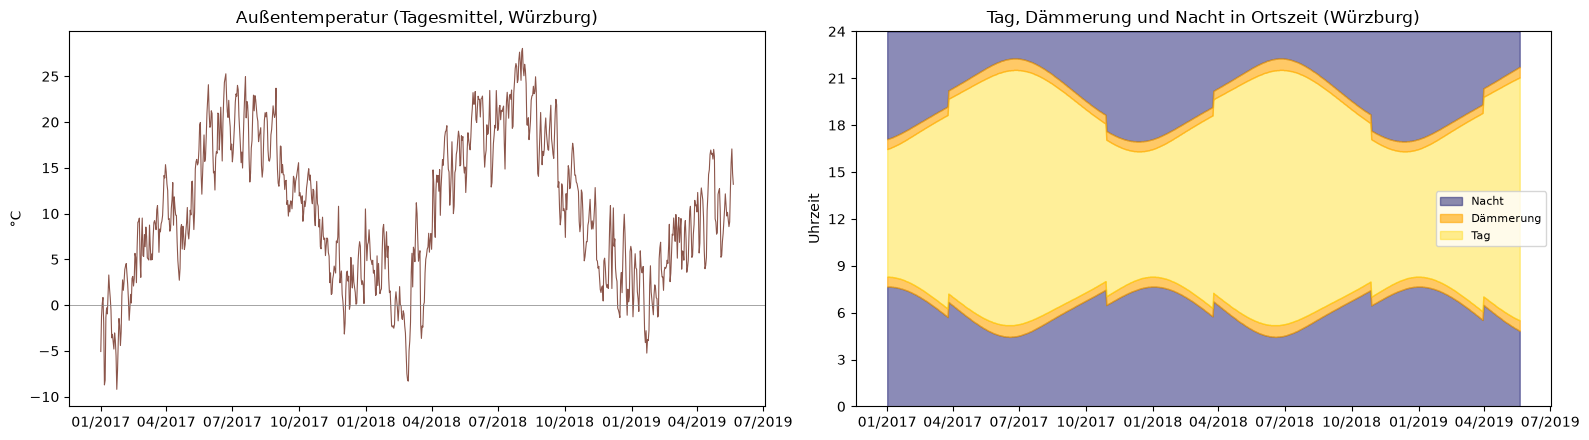

In [9]:
# --- Grafik: Außentemperatur und Sonnenzeiten ---
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))                          # zwei Diagramme nebeneinander

tagesmittel = w.set_index("zeit_utc")["aussentemperatur_c"].resample("D").mean()   # Tagesmittel
ax[0].plot(tagesmittel.index, tagesmittel, color="#8c564b", lw=0.8)   # Kategoriefarbe (Farbregel: Rot nur für Bewertungen)
ax[0].axhline(0, color="grey", lw=0.5)                                   # Nulllinie
ax[0].set(title=f"Außentemperatur (Tagesmittel, {w['station_temperatur'].mode()[0]})", ylabel="°C")

lokal = lambda s: s.dt.tz_convert(ZEITZONE)                       # UTC → Ortszeit
dezimal = lambda s: lokal(s).dt.hour + lokal(s).dt.minute / 60           # Uhrzeit als Dezimalzahl (z. B. 21,5)
d = pd.to_datetime(sonne["datum"])
ax[1].fill_between(d, 0, dezimal(sonne["daemmerung_beginn_utc"]), color="midnightblue", alpha=0.5, label="Nacht")
ax[1].fill_between(d, dezimal(sonne["daemmerung_ende_utc"]), 24, color="midnightblue", alpha=0.5)
ax[1].fill_between(d, dezimal(sonne["daemmerung_beginn_utc"]), dezimal(sonne["sonnenaufgang_utc"]), color="orange", alpha=0.6, label="Dämmerung")
ax[1].fill_between(d, dezimal(sonne["sonnenaufgang_utc"]), dezimal(sonne["sonnenuntergang_utc"]), color="gold", alpha=0.4, label="Tag")
ax[1].fill_between(d, dezimal(sonne["sonnenuntergang_utc"]), dezimal(sonne["daemmerung_ende_utc"]), color="orange", alpha=0.6)
ax[1].set(title=f"Tag, Dämmerung und Nacht in Ortszeit ({ORT['name']})", ylabel="Uhrzeit", ylim=(0, 24), yticks=range(0, 25, 3))
ax[1].legend(loc="center right", fontsize=8)
for a in ax:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))           # x-Achse: Monat/Jahr

plt.tight_layout()
BILDER.mkdir(parents=True, exist_ok=True)                           # Bildordner je Stadt
plt.savefig(BILDER / "n3_wetter_sonne.png", dpi=120)      # Grafik speichern
plt.show()

**Ergebnis:** Die Grafik (gespeichert in `04_images/<stadt>/n3_wetter_sonne.png`) zeigt links die Außentemperatur (Tagesmittel) mit Jahresgang, rechts Tag und Dämmerung über das Jahr; die Sommerzeit ist als Sprung im März/Oktober sichtbar.

Prüfpunkte: Jahresgang plausibel? Kälte- und Hitzephasen erkennbar (z. B. Frost Ende Februar/Anfang März 2018, Hitzesommer 2018)? Sonnenuntergang im Juni deutlich später als im Dezember?

## 9. Speichern nach silver/cleaned

**Wohin?** `cleaned/<stadt>/wetter/wetter_<stadt>_cleaned__<UTC-Zeitstempel>_UTC.csv` (stündlich) und `cleaned/<stadt>/sonne/sonne_<stadt>_cleaned__<UTC-Zeitstempel>_UTC.csv` (täglich) – jede Ausführung erzeugt eine neue Version; ältere Versionen wandern automatisch in das `_archiv` des Ordners.

**Kontrollwert:** 2 neue Dateien

In [10]:
# --- Speichern mit UTC-Zeitstempel (neue Version je Lauf) ---
for name_ordner, tabelle in [("wetter", w), ("sonne", sonne)]:
    ordner = CLEANED / name_ordner                                         # Zielordner
    ordner.mkdir(parents=True, exist_ok=True)                              # anlegen, falls nötig
    ziel = ordner / f"{name_ordner}_{STADT}_cleaned__{stempel}_UTC.csv"  # Dateiname mit Zeitstempel
    tabelle.to_csv(ziel, index=False)                                      # speichern
    for alt in sorted(ordner.glob(f"{name_ordner}_{STADT}_cleaned__*_UTC.csv")):  # ältere Versionen ins _archiv des Ordners (nichts wird gelöscht)
        if alt != ziel:
            (ordner / "_archiv").mkdir(exist_ok=True)
            alt.rename(ordner / "_archiv" / alt.name)
    print(f"gespeichert: {ziel.relative_to(PROJEKT)}  ({len(tabelle):,} Zeilen)")

gespeichert: 02_daten_ITS-Data/lakehouse/silver/cleaned/wurzburg/wetter/wetter_wurzburg_cleaned__2026-10-05_053908_UTC.csv  (20,881 Zeilen)
gespeichert: 02_daten_ITS-Data/lakehouse/silver/cleaned/wurzburg/sonne/sonne_wurzburg_cleaned__2026-10-05_053908_UTC.csv  (870 Zeilen)


**Ergebnis:** 2 Dateien in `silver/cleaned/<stadt>/wetter/` und `…/sonne/` gespeichert (Zeilen in der Ausgabe).

| Kontrollwerte | Wetter (Stunden) · Sonne (Tage) |
| :-- | :-- |
| Schwartau | 21.145 · 881 |
| Würzburg | 20.881 · 870 |

## Zusammenfassung N3

| Datensatz | Takt | Inhalt | Quelle |
| :-- | :-- | :-- | :-- |
| wetter | stündlich | Außentemperatur, Niederschlag, Sonnenschein, Wind, Luftfeuchte, Bewölkung, Luftdruck, Taupunkt, Windrichtung, Windböen, Sonnenstrahlung, Wetterlage, Stationen, Sonnenhöhe, Tageszeit | Bright Sky / DWD |
| sonne | täglich | Dämmerungsbeginn, Sonnenaufgang, Sonnenuntergang, Dämmerungsende, Tageslänge | NOAA-Berechnung, gegengeprüft mit Open-Meteo |

Befunde: **W1** Außenwerte kommen je Messgröße von der Station mit dem größten Anteil (Schwartau überwiegend Lübeck-Blankensee 13 km, Würzburg Station Würzburg 1,5 km) · **W2** Sonnenschein nachts fehlend → 0 gesetzt.

Nächster Schritt: N4 Gold (Stundentabelle), danach N5 Analyse – Flugverhalten nach Monat, Tageszeit (Tag · Dämmerung · Nacht) und Außentemperatur in 5-Grad-Stufen (Pflichtenheft PH-ITS-002, Schritt 3.7).